In [1]:
print("Hello")

Hello


In [2]:
%pip install numpy pandas matplotlib scikit-learn seaborn xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import metrics

### Importing the Boston House Price Dataset

In [4]:
house_price_dataset = pd.read_csv("BostonHousing.csv")

In [5]:
house_price_dataset.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,price
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [6]:
print(house_price_dataset)

        crim    zn  indus  chas    nox     rm   age     dis  rad  tax  \
0    0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296   
1    0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242   
2    0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242   
3    0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222   
4    0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222   
..       ...   ...    ...   ...    ...    ...   ...     ...  ...  ...   
501  0.06263   0.0  11.93     0  0.573  6.593  69.1  2.4786    1  273   
502  0.04527   0.0  11.93     0  0.573  6.120  76.7  2.2875    1  273   
503  0.06076   0.0  11.93     0  0.573  6.976  91.0  2.1675    1  273   
504  0.10959   0.0  11.93     0  0.573  6.794  89.3  2.3889    1  273   
505  0.04741   0.0  11.93     0  0.573  6.030  80.8  2.5050    1  273   

     ptratio       b  lstat  price  
0       15.3  396.90   4.98   24.0  
1       17.8  396.90   9.14   21.6  
2       17.8

In [7]:
# Checking the no of rows and columns
house_price_dataset.shape

(506, 14)

In [8]:
# Check for missing values
house_price_dataset.isnull().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         5
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
price      0
dtype: int64

In [9]:
# Replace missing values with the median
house_price_dataset['rm'] = house_price_dataset['rm'].fillna(
    house_price_dataset['rm'].median()
)

In [10]:
# Check for missing values
house_price_dataset.isnull().sum()

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
price      0
dtype: int64

In [11]:
# statistical measures of the dataset
house_price_dataset.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,price
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.283587,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702126,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208000,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.618750,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


### Understanding the correlation btwn various features in the dataset

### 1. Positive correlation

### 2. Negative correlation

In [12]:
correlation = house_price_dataset.corr()

<Axes: >

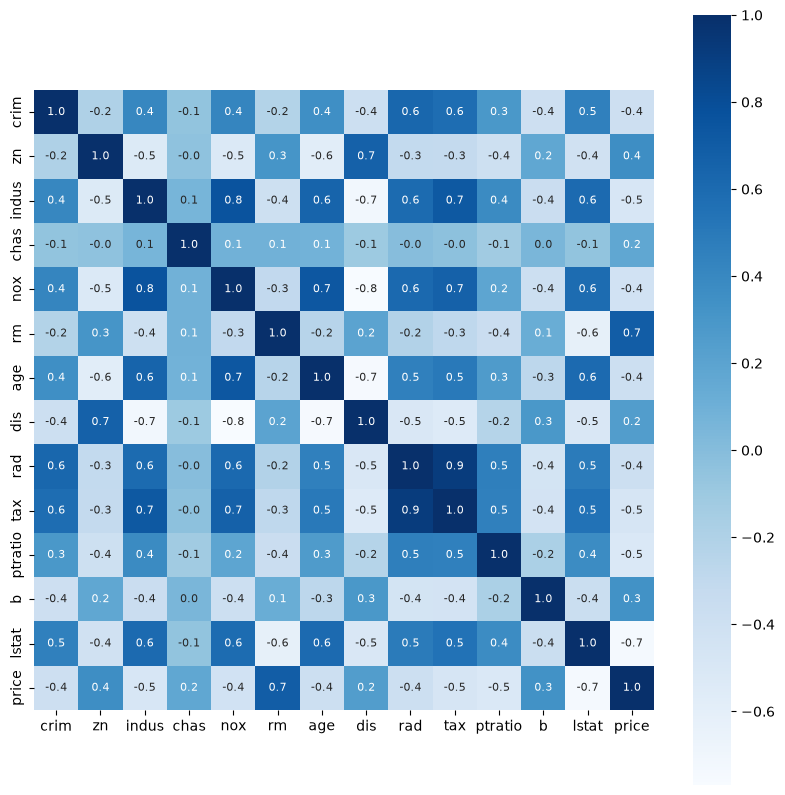

In [13]:
# Construction  a heatmap to understand the correlation
plt.figure(figsize=(10,10))
sns.heatmap(correlation, cbar=True, square=True, fmt=".1f", annot=True, annot_kws={"size": 8}, cmap='Blues')

### Splitting the data and the target

In [14]:
X = house_price_dataset.drop(['price'], axis=1)
Y = house_price_dataset['price']

In [15]:
print(X)

        crim    zn  indus  chas    nox     rm   age     dis  rad  tax  \
0    0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296   
1    0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242   
2    0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242   
3    0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222   
4    0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222   
..       ...   ...    ...   ...    ...    ...   ...     ...  ...  ...   
501  0.06263   0.0  11.93     0  0.573  6.593  69.1  2.4786    1  273   
502  0.04527   0.0  11.93     0  0.573  6.120  76.7  2.2875    1  273   
503  0.06076   0.0  11.93     0  0.573  6.976  91.0  2.1675    1  273   
504  0.10959   0.0  11.93     0  0.573  6.794  89.3  2.3889    1  273   
505  0.04741   0.0  11.93     0  0.573  6.030  80.8  2.5050    1  273   

     ptratio       b  lstat  
0       15.3  396.90   4.98  
1       17.8  396.90   9.14  
2       17.8  392.83   4.03  
3  

In [16]:
print(Y)

0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: price, Length: 506, dtype: float64


In [17]:
X.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33


### Splitting the data into training data and test data

In [18]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=2)

In [19]:
print(X.shape, X_train.shape, X_test.shape)

(506, 13) (404, 13) (102, 13)


## Model Training

## XGBoost Regressor model

In [20]:
#Loading the model
model = XGBRegressor()

In [21]:
#Training the model
model.fit(X_train, Y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Save the trained model for the Streamlit app

Run this cell after training. It saves the fitted estimator and input column order in the project directory.

In [22]:
from pathlib import Path
import joblib

model_path = Path("house_price_model.joblib")
joblib.dump({
    "model": model,
    "feature_names": X.columns.tolist(),
    "rm_median": house_price_dataset["rm"].median(),
}, model_path)
print(f"Model saved to: {model_path.resolve()}")

Model saved to: /home/julius/Documents/code/python/HOUSE_PRICE_PREDICTION/house_price_model.joblib


In your Streamlit app, load it with `joblib.load("house_price_model.joblib")`, then use the saved `feature_names` order to build the one-row input DataFrame before calling `artifact["model"].predict(input_df)`. Keep the artifact alongside the app when deploying.

## Evaluation

## Prediction on training data

In [23]:
# accurancy for prediction on training data
training_data_prediction = model.predict(X_train)

In [24]:
print(training_data_prediction)

[23.11717   20.994171  20.096422  34.69753   13.910834  13.499267
 21.998798  15.195809  10.90057   22.696712  13.805666   5.6030173
 29.802181  49.990047  34.88658   20.604557  23.380192  19.181004
 32.6881    19.602097  26.995632   8.403032  46.001682  21.700388
 27.08574   19.37382   19.305365  24.798527  22.59984   31.692022
 18.533085   8.701765  17.397078  23.703714  13.307335  10.494124
 12.699738  25.000921  19.686914  14.905453  24.214548  25.000925
 14.903375  17.002562  15.599414  12.705527  24.50954   15.012047
 49.999065  17.528643  21.19567   32.006454  15.609602  22.90318
 19.309652  18.705442  23.2973    37.20556   30.099102  33.1031
 20.983929  49.994877  13.40108    5.003966  16.504507   8.403988
 28.683165  19.503674  20.595469  45.401623  39.802593  33.399998
 19.80097   33.398373  25.294586  49.997536  12.518549  17.443024
 18.606855  22.575933  50.00252   23.805271  23.305271  23.105654
 41.701447  16.110155  31.616737  36.098965   7.00326   20.388912
 20.003757  

In [25]:
# R squared Error
score_1 = metrics.r2_score(Y_train, training_data_prediction)

# Mean absolute Error
score_2 = metrics.mean_absolute_error(Y_train, training_data_prediction)

print("R Squared Error", score_1)
print("Mean absolute error", score_2)

R Squared Error 0.999998359851856
Mean absolute error 0.008157153884963193


## Prediction of Test Data

In [26]:
# accurancy for prediction on testing data
test_data_prediction = model.predict(X_test)

In [27]:
print(test_data_prediction)

[22.86551   21.987     31.06649   30.292778   9.2174225 13.311185
 24.051939  25.46994   20.374157  19.50564   27.480082  23.678425
 20.384817  20.985502  11.860386  21.89104   19.774523  11.171835
  7.4769983 14.223087  22.514374  20.428642  35.49244   18.37263
 19.41656   18.767666  39.70795   31.510628  33.71986   19.506433
 16.358438  20.85616   30.89202   23.465462  11.881377  18.516693
 10.720987  20.76296   23.672518  21.493446  25.528442  12.878377
 29.079739   8.904566  20.941042  14.738658  34.677246  17.332571
 35.26949   15.090591  30.998156  24.207478   8.142407  33.807693
 20.547844  19.621992  19.928167  20.07877   16.76395   23.239079
 20.689157  22.194477  19.3226    30.762953  34.657097  26.030403
 49.368813  26.783236  10.529203  22.956911  15.77356    9.353244
 16.057045  17.451115  27.039036  24.214676  20.308167  22.01423
 20.15982   25.339815  32.75821   17.196724  21.18231   32.480553
 49.4637    36.63124   16.911367  25.778858  29.765182  19.884897
 20.59326   

In [28]:
# R squared Error
score_1 = metrics.r2_score(Y_test, test_data_prediction)

# Mean absolute Error
score_2 = metrics.mean_absolute_error(Y_test, test_data_prediction)

print("R Squared Error", score_1)
print("Mean absolute error", score_2)

R Squared Error 0.8868948870559723
Mean absolute error 2.1923317198659857


### Visualizing the actual prices and predicted prices

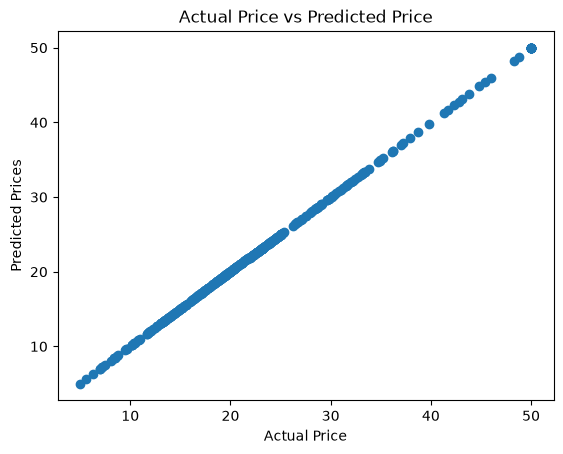

In [29]:
plt.scatter(Y_train, training_data_prediction)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Prices")
plt.title("Actual Price vs Predicted Price")
plt.show()